In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Codecademy project: Life Expectancy and GDP

Project task: "For this project, you will analyze data on GDP and life expectancy from the World Health Organization and the World Bank to try and identify the relationship between the GDP and life expectancy of six countries."

## Project scope

**Goals:** What, if any, is the relationship between life expectancy and GDP, and how does that relationship change over time? Is this relationship similar across the six countries?

**Data:** File: all_data.csv. Four columns: Country, Year, Life expectancy at birth (years), GDP. All are relevant and will be used. There is one data point for each year from year 2000 to 2015, for six countries: Chile, China, Germany, Mexico, USA, and Zimbabwe. (Oceania is not represented.) I will use all data points.

**Analysis:** Scatter plot is a natural choice for correlation. Each variable will be plotted against year. Similarities across countries will be determined by sameness of plot shape, as well as close correlation coefficient numbers.

**Limitations:** GDP does not account for population size (more populous countries will automatically have a higher GDP), and it tends to increase over time (population increases, productivity increases, inflation). So does life expectancy (sanitation, vaccines, nutrition, medicine, etc.), so some of the correlation may be shared growth. Six countries is a small sample. The file doesn’t say whether GDP is adjusted for inflation. If in current dollars, part of the rise over time is price changes. Exchange-rate movements also affect dollar GDP for countries like Germany and China. And as always, correlation does not equal causation.

In [8]:
df = pd.read_csv('all_data.csv')

df.head()

,Country,Year,Life expectancy at birth (years),GDP
0,Chile,2000,77.3,7.786093e+10
1,Chile,2001,77.3,7.097992e+10
2,Chile,2002,77.8,6.973681e+10
3,Chile,2003,77.9,7.564346e+10
4,Chile,2004,78.0,9.921039e+10


There are four columns here: Country, Year, Life expectancy at birth (years), and GDP, just like we expected. Just to be sure, let's check that there are 16 rows for each country.

In [9]:
df['Country'].value_counts()

Country
Chile                       16
China                       16
Germany                     16
Mexico                      16
United States of America    16
Zimbabwe                    16
Name: count, dtype: int64

That looks in order. Let's have a closer look at the data set we are dealing with here.

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 96 entries, 0 to 95
Data columns (total 4 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Country                           96 non-null     str    
 1   Year                              96 non-null     int64  
 2   Life expectancy at birth (years)  96 non-null     float64
 3   GDP                               96 non-null     float64
dtypes: float64(2), int64(1), str(1)
memory usage: 4.0 KB


The data set has 96 rows – exactly the number we expected – and none of them seem to be empty. The Dtypes all seem appropriate for their respective columns. Next, we might gain some insight into the data we are working with by looking at the summary statistics.

In [11]:
df.describe()

,Year,Life expectancy at birth (years),GDP
count,96.000000,96.000000,9.600000e+01
mean,2007.500000,72.789583,3.880499e+12
std,4.633971,10.672882,5.197561e+12
min,2000.000000,44.300000,4.415703e+09
25%,2003.750000,74.475000,1.733018e+11
50%,2007.500000,76.750000,1.280220e+12
75%,2011.250000,78.900000,4.067510e+12
max,2015.000000,81.000000,1.810000e+13


The year numbers are consistent with what we know. We see here that the lowest life expectancy number in the set is at just over 44 years, while the highest is 81. The lowest number is also far under the 25th percentile (74.475 years). The mean (72.790 years) is also under the 25th percentile. This suggests that the distribution for life expectancy has a fairly long tail on its left. GDP, on the other hand, has a tail on its right, and a long one at that, with its mean sitting close to the 75th percentile.

Let's take a look at what country has the lowest life expectancy. I would think it's Zimbabwe, closer to the year 2000.

In [12]:
df.idxmin()

Country                              0
Year                                 0
Life expectancy at birth (years)    84
GDP                                 88
dtype: int64

In [13]:
df.loc[84]

Country                                 Zimbabwe
Year                                        2004
Life expectancy at birth (years)            44.3
GDP                                 5805598400.0
Name: 84, dtype: object

In [14]:
df.loc[88]

Country                                 Zimbabwe
Year                                        2008
Life expectancy at birth (years)            48.2
GDP                                 4415702800.0
Name: 88, dtype: object

Interesting. Life expectancy went up between 2004 and 2008, while GDP went down. We will get back to that later.

Next, let's have a look at this data visually. But before we do that, it's a good idea to rename one of the columns. It's long and awkward and it's just unnecessary to write all of that out every time we use it.

In [36]:
df = df.rename(columns = {'Life expectancy at birth (years)': 'LifeExp'})

With that out of the way, let's plot some data on a graph. As outlined in the project scope, let's see how life expectancy and GDP develop over time.

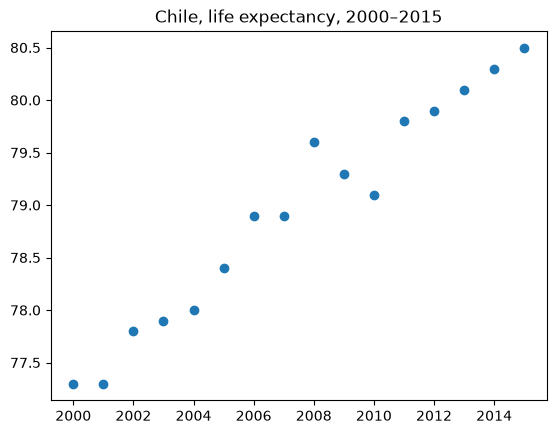

In [49]:
Chile = df[df['Country'] == 'Chile']

plt.scatter(Chile['Year'], Chile['LifeExp'])
plt.title('Chile, life expectancy, 2000–2015')
plt.show()

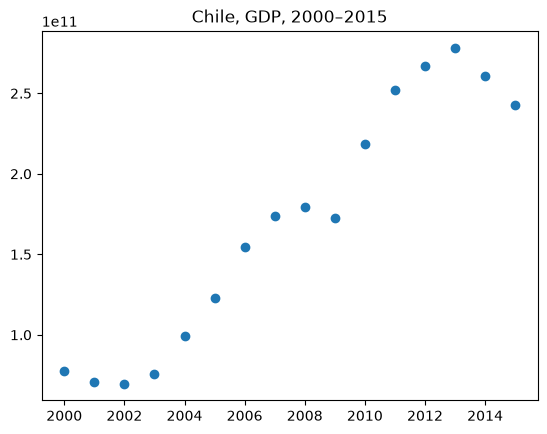

In [45]:
plt.scatter(Chile['Year'], Chile['GDP'])
plt.title('Chile, GDP, 2000–2015')
plt.show()

As expected, both life expectancy and GDP are trending upwards over time, even if there are years where they decrease. Interestingly, there are periods where one is increasing and the other is decreasing, the most notable of which is between 2013 and 2015, where the GDP fell more than it had grown the years before, whereas the life expectancy kept on growing steadily. This is a very short period of time, though.

Now let's have a look at this data side by side, so it's easier to get a sense for how they compare.

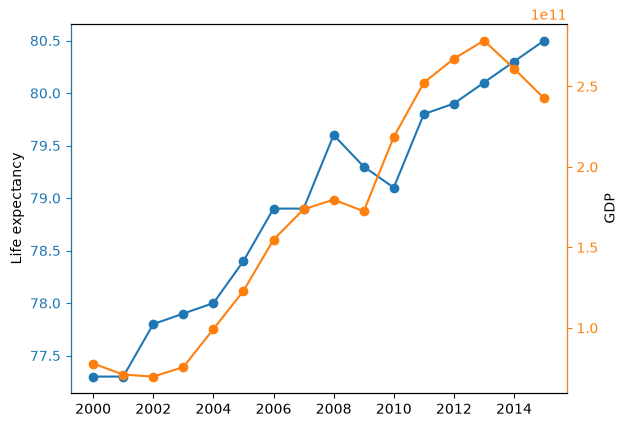

In [89]:
fig, ax1 = plt.subplots()
ax1.plot(Chile['Year'], Chile['LifeExp'], color='tab:blue', marker='o')
ax1.set_ylabel('Life expectancy')
ax1.tick_params(axis='y', colors='tab:blue')

ax2 = ax1.twinx()
ax2.plot(Chile['Year'], Chile['GDP'], color='tab:orange', marker='o')
ax2.set_ylabel('GDP')
ax2.tick_params(axis='y', colors='tab:orange')
ax2.spines['left'].set_color('tab:blue')
ax2.spines['right'].set_color('tab:orange')

They look very much correlated, right? Well, actually, Matplotlib automatically scales the y axis, so that the graph fills the figure. And it very well should. But it causes problems when comparing values directly like this. Since both mostly rise over time, the two lines will look like they are moving together almost regardless of their relationship, even though the scales are completely different.